# 05 - Monthly Risk Table

Builds the monthly risk table using `src/risk/monthly_risk.py`.

**Grain:** one row per `(ticker, month)`, where `date` is the last trading day of the month.

| Column | Meaning |
|---|---|
| `ticker` | Stock symbol (PK part 1) |
| `date` | Last trading day of the month (PK part 2) |
| `volatility_30d` | Std of daily returns over the last 30 trading days, as of `date` |
| `max_drawdown` | Largest drop from a running peak, from the start of the data up to `date` |

**Output:** `data/processed/risk_monthly.csv`

## 1. Setup

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid")

# Find the project root (the folder that contains "src") so the import works from anywhere
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "risk").exists())
sys.path.insert(0, str(ROOT))

from src.risk import monthly_risk as mr

RAW_FILE = ROOT / "data" / "raw" / "yahoo_prices_raw.csv"
OUT_FILE = ROOT / "data" / "processed" / "risk_monthly.csv"
print("Project root:", ROOT)

Project root: /home/claude


## 2. Load daily prices

In [2]:
df = pd.read_csv(RAW_FILE, parse_dates=["date"])
print("Shape:", df.shape)
print("Period:", df["date"].min().date(), "->", df["date"].max().date())
print("Tickers:", sorted(df["ticker"].unique()))

Shape: (12540, 7)
Period: 2021-01-04 -> 2025-12-30
Tickers: ['AAPL', 'AMZN', 'JNJ', 'JPM', 'KO', 'LLY', 'MSFT', 'NVDA', 'TSLA', 'XOM']


## 3. Build the monthly table

In [3]:
monthly = mr.build_monthly_risk(df)

print("Rows:", len(monthly), "| Tickers:", monthly["ticker"].nunique(),
      "| Months per ticker:", monthly.groupby("ticker").size().iloc[0])
monthly.head(12)

Rows: 600 | Tickers: 10 | Months per ticker: 60


,ticker,date,volatility_30d,max_drawdown
0,AAPL,2021-01-29,NaN,-0.078234
1,AAPL,2021-02-26,0.018851,-0.153599
2,AAPL,2021-03-31,0.021928,-0.185989
3,AAPL,2021-04-30,0.013776,-0.185989
4,AAPL,2021-05-28,0.013884,-0.185989
5,AAPL,2021-06-30,0.010347,-0.185989
6,AAPL,2021-07-30,0.012531,-0.185989
7,AAPL,2021-08-31,0.010966,-0.185989
8,AAPL,2021-09-30,0.013125,-0.185989
9,AAPL,2021-10-29,0.012514,-0.185989


`volatility_30d` is empty for the first month (January 2021): there are not yet 30 trading days of returns.

In [4]:
print("Missing values per column:")
print(monthly.isna().sum().to_string())
print("\nMonths with missing volatility:", monthly.loc[monthly["volatility_30d"].isna(), "date"].dt.strftime("%Y-%m").unique().tolist())

Missing values per column:
ticker             0
date               0
volatility_30d    10
max_drawdown       0

Months with missing volatility: ['2021-01']


## 4. Charts

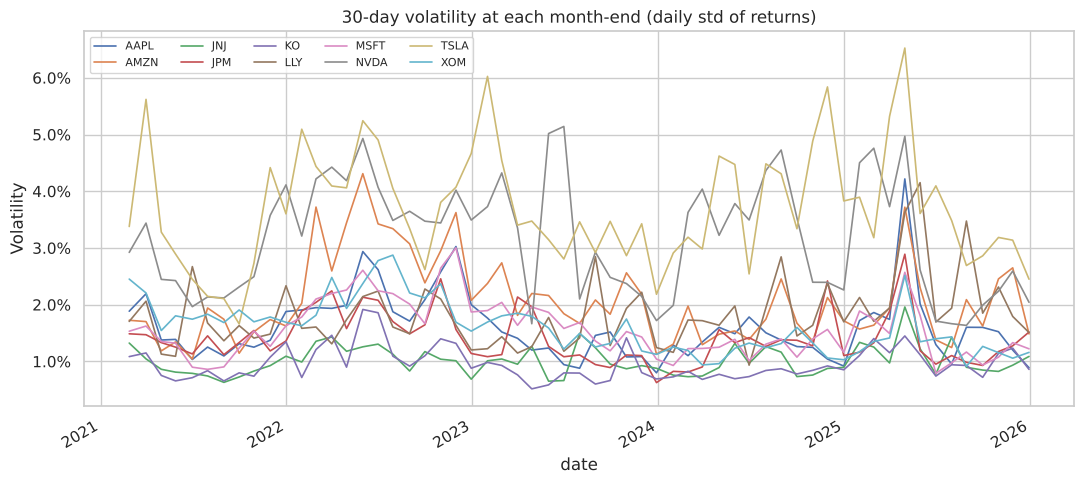

In [5]:
vol_wide = monthly.pivot(index="date", columns="ticker", values="volatility_30d")
dd_wide = monthly.pivot(index="date", columns="ticker", values="max_drawdown")

fig, ax = plt.subplots(figsize=(11, 5))
vol_wide.plot(ax=ax, linewidth=1.2)
ax.set_title("30-day volatility at each month-end (daily std of returns)")
ax.set_ylabel("Volatility")
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.legend(ncol=5, fontsize=8)
plt.tight_layout()
plt.show()

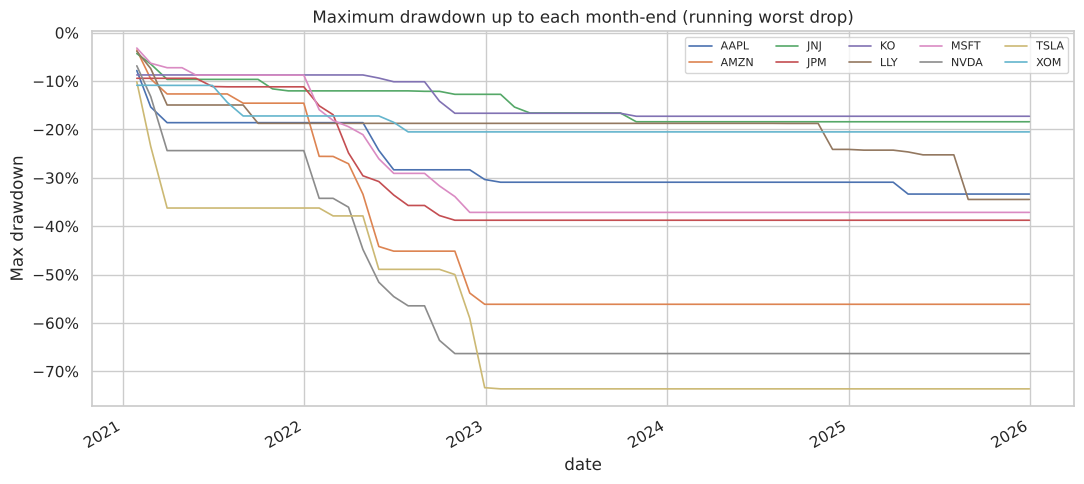

In [6]:
fig, ax = plt.subplots(figsize=(11, 5))
dd_wide.plot(ax=ax, linewidth=1.2)
ax.set_title("Maximum drawdown up to each month-end (running worst drop)")
ax.set_ylabel("Max drawdown")
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.legend(ncol=5, fontsize=8)
plt.tight_layout()
plt.show()

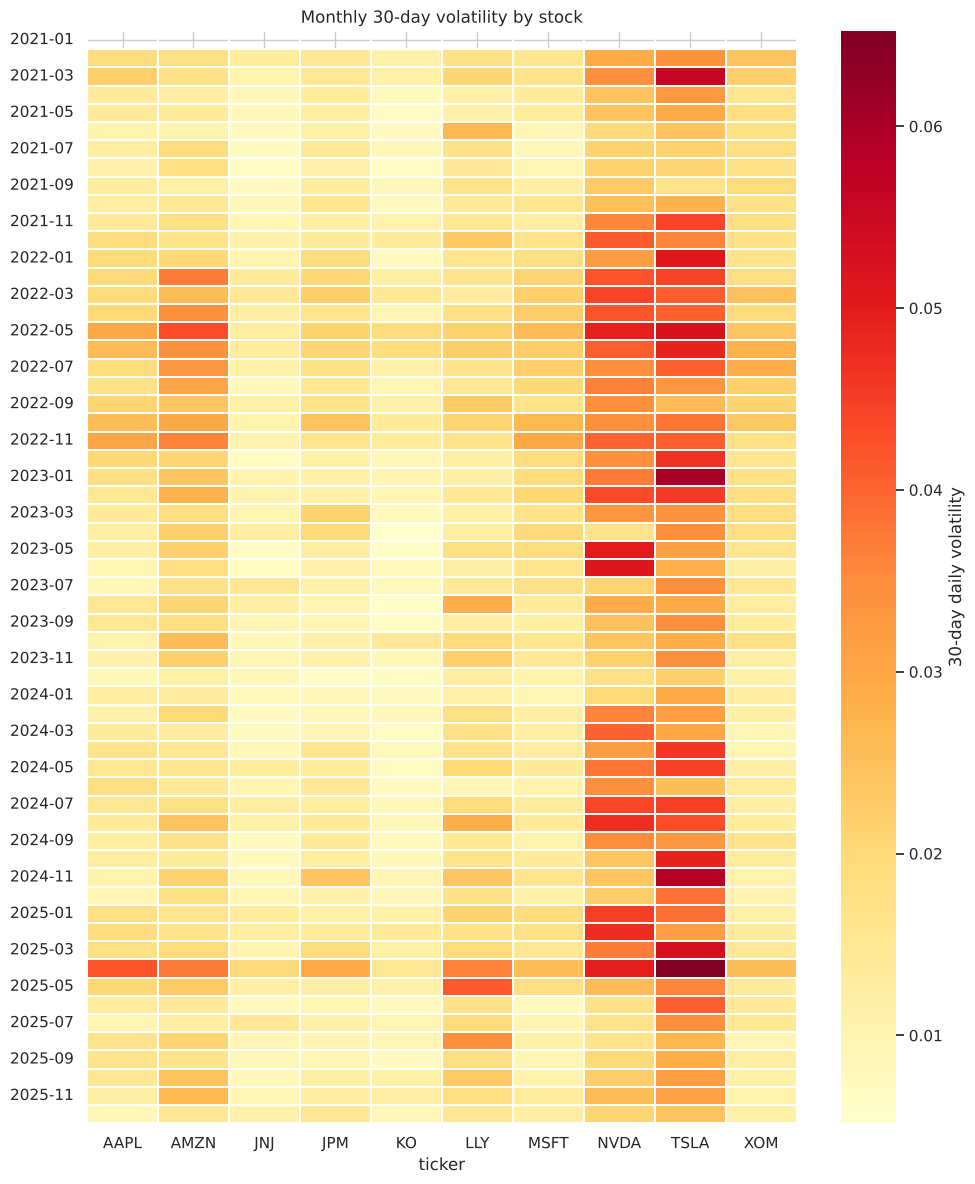

In [7]:
heat = vol_wide.copy()
heat.index = heat.index.strftime("%Y-%m")

fig, ax = plt.subplots(figsize=(10, 12))
sns.heatmap(heat, cmap="YlOrRd", linewidths=0.2, cbar_kws={"label": "30-day daily volatility"}, ax=ax)
ax.set_title("Monthly 30-day volatility by stock")
ax.set_ylabel("")
plt.tight_layout()
plt.show()

## 5. Quick checks

In [8]:
raw = df.sort_values(["ticker", "date"])
last_day = raw.groupby(["ticker", raw["date"].dt.to_period("M")])["date"].max().reset_index(drop=True)

checks = {
    "Columns match the proposed table": list(monthly.columns) == ["ticker", "date", "volatility_30d", "max_drawdown"],
    "PK (ticker, date) is unique": not monthly.duplicated(["ticker", "date"]).any(),
    "60 months for every ticker": bool((monthly.groupby("ticker").size() == 60).all()),
    "Every date is a last trading day of its month": bool(monthly["date"].isin(last_day).all()),
    "Volatility is never negative": bool((monthly["volatility_30d"].dropna() >= 0).all()),
    "Drawdown is between -100% and 0": bool(monthly["max_drawdown"].between(-1, 0).all()),
    "Drawdown never improves over time (running worst)": bool(all(
        g["max_drawdown"].is_monotonic_decreasing for _, g in monthly.groupby("ticker"))),
    "Only January 2021 has missing volatility": bool(
        monthly.loc[monthly["volatility_30d"].isna(), "date"].dt.strftime("%Y-%m").eq("2021-01").all()),
}
pd.Series(checks, name="passed").to_frame()

,passed
Columns match the proposed table,True
"PK (ticker, date) is unique",True
60 months for every ticker,True
Every date is a last trading day of its month,True
Volatility is never negative,True
Drawdown is between -100% and 0,True
Drawdown never improves over time (running worst),True
Only January 2021 has missing volatility,True


## 6. Save

In [9]:
OUT_FILE.parent.mkdir(parents=True, exist_ok=True)
monthly.to_csv(OUT_FILE, index=False)
print("Saved:", OUT_FILE)
print("Rows:", len(monthly))

Saved: /home/claude/data/processed/risk_monthly.csv
Rows: 600


## 7. Key observations

In [10]:
latest = monthly.sort_values("date").groupby("ticker").tail(1).set_index("ticker")
peak_vol = monthly.loc[monthly.groupby("ticker")["volatility_30d"].idxmax()].set_index("ticker")

print(f"Latest month-end: {latest['date'].max().date()}")
print(f"- Highest current 30d volatility: {latest['volatility_30d'].idxmax()} ({latest['volatility_30d'].max():.2%} daily)")
print(f"- Lowest current 30d volatility: {latest['volatility_30d'].idxmin()} ({latest['volatility_30d'].min():.2%} daily)")
print(f"- Deepest max drawdown so far: {latest['max_drawdown'].idxmin()} ({latest['max_drawdown'].min():.1%})")
top = peak_vol["volatility_30d"].idxmax()
print(f"- Highest monthly volatility reading ever: {top} ({peak_vol.loc[top, 'volatility_30d']:.2%} daily, {peak_vol.loc[top, 'date'].date()})")

Latest month-end: 2025-12-30
- Highest current 30d volatility: TSLA (2.45% daily)
- Lowest current 30d volatility: KO (0.86% daily)
- Deepest max drawdown so far: TSLA (-73.6%)
- Highest monthly volatility reading ever: TSLA (6.52% daily, 2025-04-30)
